In [38]:
# We start by importing all the necessary packages
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import torch
from tqdm import tqdm
import math
from Python_files import time_integration_functions as TST
from Python_files import TLM_Test as TT
from Python_files import ETLM as ETLMC
from Python_files import LETLM_ensemble as LETLMC
from Python_files import IETLM_ensemble as IETLMC
from Python_files import GETLM as GETLMC
from Python_files import GETLM_experiment_neat as GEN

from Python_files import GETLM_experiment_neat_IO2 as GENIO
#  We also need to set the precision to be higher as we are working with very small perturbations
torch.set_default_dtype(torch.float64)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [39]:
# we now define stuff as required
model = TST.rk4_L96

N = 40 # The number of grid points
dx = 1 # The spacing
F_L96 = 8 # The Lorenz 96 forcing term
dt = 0.075 # This gives a time step of six hours
timesteps =  14400 # This moves the model forward ten years
alpha = 1 # set for no reason
beta = 1 # set for no reason
model_parameters = (N, dx, dt, alpha, beta, F_L96)

spin_up_time = 1000

perturbation_size = 10**(-7)
ensemble_size = 24
num_steps = 20
trials = 200
LETLM_stencil = [[0], [-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7]]
IETLM_stencil = [[-4,-3,-2,-1,0,1,2,3], [-4,-3,-2,-1,0,1,2,3]]
GETLM_stencil = [[-2,-1,0,1], [-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7],[-2,-1,0,1]]
print(len(GETLM_stencil))

x_values = np.arange(1, num_steps+1)  


3


In [40]:
# LETLM_F = []
# IETLM_F = []
# GETLM_1_result_F = []
# GETLM_2_result_F = []
# GETLM_3_result_F = []
# GETLM_4_result_F = []
# # Spin up the model

# # we start by initialising the model with a vector of random normal noise
# x_in = torch.randn(N,1)
# # We then run the model so that the Lorenz 96 model has reached it's 'equilibrium'
# # print(x_in.size())
# for i in range(spin_up_time-1):
#     x_in = TST.run_model(x_in, model, model_parameters)
#     # print(x_in[0].size())

# x_out = TST.run_model(x_in, model, model_parameters)

# # print(type(x_out))


# # we will define out test perturbation 
# current_pert = torch.randn(N) * perturbation_size
# past_pert = torch.randn(N) * perturbation_size
# test_pert = [current_pert, past_pert]

# GETLM_1_pert = torch.hstack((current_pert, past_pert))
# GETLM_2_pert = GETLM_1_pert
# GETLM_3_pert = GETLM_1_pert
# GETLM_4_pert = GETLM_1_pert
# LETLM_pert = current_pert
# IETLM_pert = current_pert


# # test_guess = x_out + test_pert
# test_guess = [xo + tp for xo, tp in zip(x_out, test_pert)]

# # print(test_pert)


# for i in tqdm(range(num_steps)):
#     # We now generate the TLMs for the current xg
    
#     LETLM, IETLM, GETLM_1, GETLM_2, GETLM_3, GETLM_4 = GENIO.GETLM_experiment(model, model_parameters, perturbation_size, ensemble_size, 2, LETLM_stencil, IETLM_stencil, GETLM_stencil, plotted = False, spin_up_time = 1000, x_alt = x_out, pert_plots = False)




#     # run the model for 1 time step 
#     x_out = TST.run_model(x_out, model, model_parameters)
#     # X_Out = torch.hstack((x_out[0], x_out[1]))
#     X_Out = x_out[0]

#     test_guess = TST.run_model(test_guess, model, model_parameters)
#     # print(type(test_guess[0]))
#     TEST_GUESS = test_guess[0]


#     GETLM_1_pert = GETLM_1 @ GETLM_1_pert
#     # print(TEST_GUESS)
#     GETLM_2_pert = GETLM_2 @ GETLM_2_pert
#     GETLM_3_pert = GETLM_3 @ GETLM_3_pert
#     GETLM_4_pert = GETLM_4 @ GETLM_4_pert


#     GETLM_1_test = GETLM_1_pert.size(0)//2
#     GETLM_2_test = GETLM_2_pert.size(0)//2
#     GETLM_3_test = GETLM_3_pert.size(0)//2
#     GETLM_4_test = GETLM_4_pert.size(0)//2

#     # rework this to do the large state vector but then test on the single time state

#     IETLM_pert = IETLM @ IETLM_pert

#     LETLM_pert = LETLM @ LETLM_pert


#     print(GETLM_1_pert.size())



#     # compute the TLM test results
#     # print(TEST_GUESS.size())
#     IETLM_TT = TT.TLM_test(TEST_GUESS, X_Out, IETLM_pert )
#     LETLM_TT = TT.TLM_test(TEST_GUESS, X_Out, LETLM_pert )
#     GETLM_1_TT = TT.TLM_test(TEST_GUESS, X_Out, GETLM_1_test )
#     GETLM_2_TT = TT.TLM_test(TEST_GUESS, X_Out, GETLM_2_test )
#     GETLM_3_TT = TT.TLM_test(TEST_GUESS, X_Out, GETLM_3_test )
#     GETLM_4_TT = TT.TLM_test(TEST_GUESS, X_Out, GETLM_4_test )


#     LETLM_F.append(LETLM_TT)
#     IETLM_F.append(IETLM_TT)
#     GETLM_1_result_F.append(GETLM_1_TT)
#     GETLM_2_result_F.append(GETLM_2_TT)
#     GETLM_3_result_F.append(GETLM_3_TT)
#     GETLM_4_result_F.append(GETLM_4_TT)














In [41]:
LETLM_F = []
IETLM_F = []

GETLM_1_result_F = []
GETLM_2_result_F = []
GETLM_3_result_F = []
GETLM_4_result_F = []

# --------------------------------------------------
# Spin up the reference model
# --------------------------------------------------

x_in = torch.randn(N, 1)

for i in range(spin_up_time - 1):
    x_in = TST.run_model(x_in, model, model_parameters)

x_out = TST.run_model(x_in, model, model_parameters)

# --------------------------------------------------
# Generate the initial test perturbations
# --------------------------------------------------

current_pert = torch.randn(N) * perturbation_size
past_pert = torch.randn(N) * perturbation_size

test_pert = (current_pert, past_pert)

# Initialise the perturbed trajectory.
# Keep this ordering consistent with the model's state convention.
test_guess = [
    xo + tp for xo, tp in zip(x_out, test_pert)
]

# --------------------------------------------------
# Generate the ensemble and time-dependent GETLM matrices
# --------------------------------------------------

(
    test_final_pert,
    Ensemble_final,
    Ensembles,
    test_guess,
    unpert_run
) = GETLMC.GETLM_ensemble_generator_mult(
    x_out,
    ensemble_size,
    perturbation_size,
    model,
    model_parameters,
    test_pert,
    number_of_steps=num_steps
)

GETLMS_1 = []
GETLMS_2 = []
GETLMS_3 = []
GETLMS_4 = []

IETLMS = []
LETLMS = []

for i in range(len(Ensemble_final) - 2):

    Chi = Ensemble_final[i + 2]
    Xi = Ensemble_final[i + 1]
    X = Ensemble_final[i]

    # GETLM with 1, 2, 3 and 4 zero eigenvalues
    for k, store in [
        (1, GETLMS_1),
        (2, GETLMS_2),
        (3, GETLMS_3),
        (4, GETLMS_4)
    ]:
        N_tilde_G, L_tilde_G, K_tilde_G = (
            GETLMC.GETLM_generator(
                Chi,
                Xi,
                X,
                GETLM_stencil,
                model_parameters,
                ensemble_size,
                k,
                plot=False
            )
        )

        store.append([
            N_tilde_G,
            L_tilde_G,
            K_tilde_G
        ])

    # IETLM
    N_tilde_I, L_tilde_I = IETLMC.IETLM_generator(
        Chi,
        Xi,
        IETLM_stencil,
        model_parameters,
        ensemble_size
    )

    IETLMS.append(
        torch.pinverse(N_tilde_I) @ L_tilde_I
    )

    # LETLM
    M_temp = LETLMC.LETLM_generator(
        Chi,
        Xi,
        LETLM_stencil,
        model_parameters,
        ensemble_size
    )

    LETLMS.append(M_temp)

# --------------------------------------------------
# Initialise perturbations at the starting time
# --------------------------------------------------

starting_time = 1

test_0 = test_final_pert[1 + starting_time]

IETLM_test = test_0.clone()
LETLM_test = test_0.clone()

GETLM_test_future_1 = test_0.clone()
GETLM_test_future_2 = test_0.clone()
GETLM_test_future_3 = test_0.clone()
GETLM_test_future_4 = test_0.clone()

GETLM_test_current_1 = test_final_pert[starting_time].clone()
GETLM_test_current_2 = test_final_pert[starting_time].clone()
GETLM_test_current_3 = test_final_pert[starting_time].clone()
GETLM_test_current_4 = test_final_pert[starting_time].clone()

# --------------------------------------------------
# Test the initial perturbation
# --------------------------------------------------

index = 1 + starting_time

IETLM_TT = TT.TLM_test(
    test_guess[index], unpert_run[index], test_0
)
LETLM_TT = TT.TLM_test(
    test_guess[index], unpert_run[index], test_0
)

GETLM_1_TT = TT.TLM_test(
    test_guess[index], unpert_run[index], test_0
)
GETLM_2_TT = TT.TLM_test(
    test_guess[index], unpert_run[index], test_0
)
GETLM_3_TT = TT.TLM_test(
    test_guess[index], unpert_run[index], test_0
)
GETLM_4_TT = TT.TLM_test(
    test_guess[index], unpert_run[index], test_0
)

LETLM_F.append(LETLM_TT)
IETLM_F.append(IETLM_TT)

GETLM_1_result_F.append(GETLM_1_TT)
GETLM_2_result_F.append(GETLM_2_TT)
GETLM_3_result_F.append(GETLM_3_TT)
GETLM_4_result_F.append(GETLM_4_TT)

# --------------------------------------------------
# Propagate all TLM perturbations
# --------------------------------------------------

for i in range(len(test_final_pert) - 3):

    index = i + 2 + starting_time

    # ----------------------------------------------
    # IETLM
    # ----------------------------------------------

    ietlm = IETLMS[i + starting_time]
    IETLM_test = ietlm @ IETLM_test

    IETLM_TT = TT.TLM_test(
        test_guess[index],
        unpert_run[index],
        IETLM_test
    )

    IETLM_F.append(IETLM_TT)

    # ----------------------------------------------
    # LETLM
    # ----------------------------------------------

    letlm = LETLMS[i + starting_time]
    LETLM_test = letlm @ LETLM_test

    LETLM_TT = TT.TLM_test(
        test_guess[index],
        unpert_run[index],
        LETLM_test
    )

    LETLM_F.append(LETLM_TT)

    # ----------------------------------------------
    # GETLM 1: shift past/current and propagate
    # ----------------------------------------------

    GETLM_test_past_1 = GETLM_test_current_1.clone()
    GETLM_test_current_1 = GETLM_test_future_1.clone()

    N1, L1, K1 = GETLMS_1[i + starting_time]

    NL1 = torch.pinverse(N1) @ L1
    NK1 = torch.pinverse(N1) @ K1

    GETLM_test_future_1 = (
        NL1 @ GETLM_test_current_1
        + NK1 @ GETLM_test_past_1
    )

    # ----------------------------------------------
    # GETLM 2
    # ----------------------------------------------

    GETLM_test_past_2 = GETLM_test_current_2.clone()
    GETLM_test_current_2 = GETLM_test_future_2.clone()

    N2, L2, K2 = GETLMS_2[i + starting_time]

    NL2 = torch.pinverse(N2) @ L2
    NK2 = torch.pinverse(N2) @ K2

    GETLM_test_future_2 = (
        NL2 @ GETLM_test_current_2
        + NK2 @ GETLM_test_past_2
    )

    # ----------------------------------------------
    # GETLM 3
    # ----------------------------------------------

    GETLM_test_past_3 = GETLM_test_current_3.clone()
    GETLM_test_current_3 = GETLM_test_future_3.clone()

    N3, L3, K3 = GETLMS_3[i + starting_time]

    NL3 = torch.pinverse(N3) @ L3
    NK3 = torch.pinverse(N3) @ K3

    GETLM_test_future_3 = (
        NL3 @ GETLM_test_current_3
        + NK3 @ GETLM_test_past_3
    )

    # ----------------------------------------------
    # GETLM 4
    # ----------------------------------------------

    GETLM_test_past_4 = GETLM_test_current_4.clone()
    GETLM_test_current_4 = GETLM_test_future_4.clone()

    N4, L4, K4 = GETLMS_4[i + starting_time]

    NL4 = torch.pinverse(N4) @ L4
    NK4 = torch.pinverse(N4) @ K4

    GETLM_test_future_4 = (
        NL4 @ GETLM_test_current_4
        + NK4 @ GETLM_test_past_4
    )

    # ----------------------------------------------
    # Compare against the nonlinear model difference
    # ----------------------------------------------

    GETLM_1_TT = TT.TLM_test(
        test_guess[index],
        unpert_run[index],
        GETLM_test_future_1
    )

    GETLM_2_TT = TT.TLM_test(
        test_guess[index],
        unpert_run[index],
        GETLM_test_future_2
    )

    GETLM_3_TT = TT.TLM_test(
        test_guess[index],
        unpert_run[index],
        GETLM_test_future_3
    )

    GETLM_4_TT = TT.TLM_test(
        test_guess[index],
        unpert_run[index],
        GETLM_test_future_4
    )

    GETLM_1_result_F.append(GETLM_1_TT)
    GETLM_2_result_F.append(GETLM_2_TT)
    GETLM_3_result_F.append(GETLM_3_TT)
    GETLM_4_result_F.append(GETLM_4_TT)

In [43]:


num_trials = trials  # Change this to your desired number of trials

# Accumulators to store results across all trials
LETLM_trials = []
IETLM_trials = []
GETLM_1_trials = []
GETLM_2_trials = []
GETLM_3_trials = []
GETLM_4_trials = []

for trial in tqdm(range(num_trials)):
    LETLM_F = []
    IETLM_F = []
    GETLM_1_result_F = []
    GETLM_2_result_F = []
    GETLM_3_result_F = []
    GETLM_4_result_F = []

    # --------------------------------------------------
    # Spin up the reference model
    # --------------------------------------------------

    x_in = torch.randn(N, 1)

    for i in range(spin_up_time - 1):
        x_in = TST.run_model(x_in, model, model_parameters)

    x_out = TST.run_model(x_in, model, model_parameters)

    # --------------------------------------------------
    # Generate the initial test perturbations
    # --------------------------------------------------

    current_pert = torch.randn(N) * perturbation_size
    past_pert = torch.randn(N) * perturbation_size

    test_pert = (current_pert, past_pert)

    # Initialise the perturbed trajectory.
    test_guess = [
        xo + tp for xo, tp in zip(x_out, test_pert)
    ]

    # --------------------------------------------------
    # Generate the ensemble and time-dependent GETLM matrices
    # --------------------------------------------------

    (
        test_final_pert,
        Ensemble_final,
        Ensembles,
        test_guess,
        unpert_run
    ) = GETLMC.GETLM_ensemble_generator_mult(
        x_out,
        ensemble_size,
        perturbation_size,
        model,
        model_parameters,
        test_pert,
        number_of_steps=num_steps
    )

    GETLMS_1 = []
    GETLMS_2 = []
    GETLMS_3 = []
    GETLMS_4 = []

    IETLMS = []
    LETLMS = []

    for i in range(len(Ensemble_final) - 2):

        Chi = Ensemble_final[i + 2]
        Xi = Ensemble_final[i + 1]
        X = Ensemble_final[i]

        # GETLM with 1, 2, 3 and 4 zero eigenvalues
        for k, store in [
            (1, GETLMS_1),
            (2, GETLMS_2),
            (3, GETLMS_3),
            (4, GETLMS_4)
        ]:
            N_tilde_G, L_tilde_G, K_tilde_G = (
                GETLMC.GETLM_generator(
                    Chi,
                    Xi,
                    X,
                    GETLM_stencil,
                    model_parameters,
                    ensemble_size,
                    k,
                    plot=False
                )
            )

            store.append([
                N_tilde_G,
                L_tilde_G,
                K_tilde_G
            ])

        # IETLM
        N_tilde_I, L_tilde_I = IETLMC.IETLM_generator(
            Chi,
            Xi,
            IETLM_stencil,
            model_parameters,
            ensemble_size
        )

        IETLMS.append(
            torch.pinverse(N_tilde_I) @ L_tilde_I
        )

        # LETLM
        M_temp = LETLMC.LETLM_generator(
            Chi,
            Xi,
            LETLM_stencil,
            model_parameters,
            ensemble_size
        )

        LETLMS.append(M_temp)

    # --------------------------------------------------
    # Initialise perturbations at the starting time
    # --------------------------------------------------

    starting_time = 1

    test_0 = test_final_pert[1 + starting_time]

    IETLM_test = test_0.clone()
    LETLM_test = test_0.clone()

    GETLM_test_future_1 = test_0.clone()
    GETLM_test_future_2 = test_0.clone()
    GETLM_test_future_3 = test_0.clone()
    GETLM_test_future_4 = test_0.clone()

    GETLM_test_current_1 = test_final_pert[starting_time].clone()
    GETLM_test_current_2 = test_final_pert[starting_time].clone()
    GETLM_test_current_3 = test_final_pert[starting_time].clone()
    GETLM_test_current_4 = test_final_pert[starting_time].clone()

    # --------------------------------------------------
    # Test the initial perturbation
    # --------------------------------------------------

    index = 1 + starting_time

    IETLM_TT = TT.TLM_test(
        test_guess[index], unpert_run[index], test_0
    )
    LETLM_TT = TT.TLM_test(
        test_guess[index], unpert_run[index], test_0
    )

    GETLM_1_TT = TT.TLM_test(
        test_guess[index], unpert_run[index], test_0
    )
    GETLM_2_TT = TT.TLM_test(
        test_guess[index], unpert_run[index], test_0
    )
    GETLM_3_TT = TT.TLM_test(
        test_guess[index], unpert_run[index], test_0
    )
    GETLM_4_TT = TT.TLM_test(
        test_guess[index], unpert_run[index], test_0
    )

    LETLM_F.append(LETLM_TT)
    IETLM_F.append(IETLM_TT)

    GETLM_1_result_F.append(GETLM_1_TT)
    GETLM_2_result_F.append(GETLM_2_TT)
    GETLM_3_result_F.append(GETLM_3_TT)
    GETLM_4_result_F.append(GETLM_4_TT)

    # --------------------------------------------------
    # Propagate all TLM perturbations
    # --------------------------------------------------

    for i in range(len(test_final_pert) - 3):

        index = i + 2 + starting_time

        # IETLM
        ietlm = IETLMS[i + starting_time]
        IETLM_test = ietlm @ IETLM_test
        IETLM_TT = TT.TLM_test(
            test_guess[index], unpert_run[index], IETLM_test
        )
        IETLM_F.append(IETLM_TT)

        # LETLM
        letlm = LETLMS[i + starting_time]
        LETLM_test = letlm @ LETLM_test
        LETLM_TT = TT.TLM_test(
            test_guess[index], unpert_run[index], LETLM_test
        )
        LETLM_F.append(LETLM_TT)

        # GETLM 1
        GETLM_test_past_1 = GETLM_test_current_1.clone()
        GETLM_test_current_1 = GETLM_test_future_1.clone()
        N1, L1, K1 = GETLMS_1[i + starting_time]
        GETLM_test_future_1 = (
            torch.pinverse(N1) @ L1 @ GETLM_test_current_1
            + torch.pinverse(N1) @ K1 @ GETLM_test_past_1
        )

        # GETLM 2
        GETLM_test_past_2 = GETLM_test_current_2.clone()
        GETLM_test_current_2 = GETLM_test_future_2.clone()
        N2, L2, K2 = GETLMS_2[i + starting_time]
        GETLM_test_future_2 = (
            torch.pinverse(N2) @ L2 @ GETLM_test_current_2
            + torch.pinverse(N2) @ K2 @ GETLM_test_past_2
        )

        # GETLM 3
        GETLM_test_past_3 = GETLM_test_current_3.clone()
        GETLM_test_current_3 = GETLM_test_future_3.clone()
        N3, L3, K3 = GETLMS_3[i + starting_time]
        GETLM_test_future_3 = (
            torch.pinverse(N3) @ L3 @ GETLM_test_current_3
            + torch.pinverse(N3) @ K3 @ GETLM_test_past_3
        )

        # GETLM 4
        GETLM_test_past_4 = GETLM_test_current_4.clone()
        GETLM_test_current_4 = GETLM_test_future_4.clone()
        N4, L4, K4 = GETLMS_4[i + starting_time]
        GETLM_test_future_4 = (
            torch.pinverse(N4) @ L4 @ GETLM_test_current_4
            + torch.pinverse(N4) @ K4 @ GETLM_test_past_4
        )

        # Compare GETLM against nonlinear model difference
        GETLM_1_TT = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_1)
        GETLM_2_TT = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_2)
        GETLM_3_TT = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_3)
        GETLM_4_TT = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_4)

        GETLM_1_result_F.append(GETLM_1_TT)
        GETLM_2_result_F.append(GETLM_2_TT)
        GETLM_3_result_F.append(GETLM_3_TT)
        GETLM_4_result_F.append(GETLM_4_TT)

    # Append results of this trial to trial accumulators
    LETLM_trials.append(LETLM_F)
    IETLM_trials.append(IETLM_F)
    GETLM_1_trials.append(GETLM_1_result_F)
    GETLM_2_trials.append(GETLM_2_result_F)
    GETLM_3_trials.append(GETLM_3_result_F)
    GETLM_4_trials.append(GETLM_4_result_F)

# --------------------------------------------------
# Compute the average across all trials element-wise
# --------------------------------------------------
LETLM_F = torch.stack([torch.tensor(t) for t in LETLM_trials]).mean(dim=0).tolist()
IETLM_F = torch.stack([torch.tensor(t) for t in IETLM_trials]).mean(dim=0).tolist()
GETLM_1_result_F = torch.stack([torch.tensor(t) for t in GETLM_1_trials]).mean(dim=0).tolist()
GETLM_2_result_F = torch.stack([torch.tensor(t) for t in GETLM_2_trials]).mean(dim=0).tolist()
GETLM_3_result_F = torch.stack([torch.tensor(t) for t in GETLM_3_trials]).mean(dim=0).tolist()
GETLM_4_result_F = torch.stack([torch.tensor(t) for t in GETLM_4_trials]).mean(dim=0).tolist()

  3%|▎         | 6/200 [00:05<03:09,  1.02it/s]


KeyboardInterrupt: 

In [46]:
import torch
from tqdm import tqdm

num_trials = 10
num_steps = 20

# Accumulators to store results across all trials
LETLM_trials = []
IETLM_trials = []
GETLM_1_trials = []
GETLM_2_trials = []
GETLM_3_trials = []
GETLM_4_trials = []

for trial in tqdm(range(num_trials), desc="Trials"):
    LETLM_F, IETLM_F = [], []
    GETLM_1_result_F, GETLM_2_result_F = [], []
    GETLM_3_result_F, GETLM_4_result_F = [], []

    # --------------------------------------------------
    # 1. Spin up the reference model
    # --------------------------------------------------
    x_in = torch.randn(N, 1)
    for i in range(spin_up_time - 1):
        x_in = TST.run_model(x_in, model, model_parameters)
    
    # x_out is a list containing [current_state, past_state]
    x_out = TST.run_model(x_in, model, model_parameters)

    # --------------------------------------------------
    # 2. Initialise true perturbed trajectories
    # --------------------------------------------------
    # Create 1D perturbations
    current_pert = torch.randn(N) * perturbation_size
    past_pert = torch.randn(N) * perturbation_size

    # test_guess is also a list [perturbed_current, perturbed_past]
    # We must add the perturbations to the respective tensors inside the list
    test_guess = [
        x_out[0] + current_pert.view_as(x_out[0]), 
        x_out[1] + past_pert.view_as(x_out[1])
    ]

    # --------------------------------------------------
    # 3. Initialise tangent linear perturbations (1D)
    # --------------------------------------------------
    # Stack the 1D perturbations for the GETLM history operators
    GETLM_1_pert = torch.hstack((current_pert, past_pert))
    GETLM_2_pert = GETLM_1_pert.clone()
    GETLM_3_pert = GETLM_1_pert.clone()
    GETLM_4_pert = GETLM_1_pert.clone()
    
    LETLM_pert = current_pert.clone()
    IETLM_pert = current_pert.clone()

    # --------------------------------------------------
    # 4. Rolling Step Loop
    # --------------------------------------------------
    for step in range(num_steps):
        
        # Generate the TLMs around the current unperturbed state
        LETLM, IETLM, GETLM_1, GETLM_2, GETLM_3, GETLM_4 = GENIO.GETLM_experiment(
            model, model_parameters, perturbation_size, ensemble_size, 2, 
            LETLM_stencil, IETLM_stencil, GETLM_stencil, 
            plotted=False, spin_up_time=1000, x_alt=x_out, pert_plots=False
        )

        # Advance BOTH nonlinear models by 1 step
        x_out = TST.run_model(x_out, model, model_parameters)
        test_guess = TST.run_model(test_guess, model, model_parameters)

        # Propagate the linear perturbations
        GETLM_1_pert = GETLM_1 @ GETLM_1_pert
        GETLM_2_pert = GETLM_2 @ GETLM_2_pert
        GETLM_3_pert = GETLM_3 @ GETLM_3_pert
        GETLM_4_pert = GETLM_4 @ GETLM_4_pert
        
        IETLM_pert = IETLM @ IETLM_pert
        LETLM_pert = LETLM @ LETLM_pert

        # --- Strict Shape Matching for Tests ---
        # Get the single current state [Size: 40]
        X_Out_single = x_out[0].squeeze()
        TEST_GUESS_single = test_guess[0].squeeze()
        
        # Get the stacked current and past states [Size: 80]
        X_Out_stacked = torch.hstack((x_out[0].squeeze(), x_out[1].squeeze()))
        TEST_GUESS_stacked = torch.hstack((test_guess[0].squeeze(), test_guess[1].squeeze()))

        # Compare linear approx against the true nonlinear difference
        IETLM_TT = TT.TLM_test(TEST_GUESS_single, X_Out_single, IETLM_pert)
        LETLM_TT = TT.TLM_test(TEST_GUESS_single, X_Out_single, LETLM_pert)
        
        GETLM_1_TT = TT.TLM_test(TEST_GUESS_stacked, X_Out_stacked, GETLM_1_pert)
        GETLM_2_TT = TT.TLM_test(TEST_GUESS_stacked, X_Out_stacked, GETLM_2_pert)
        GETLM_3_TT = TT.TLM_test(TEST_GUESS_stacked, X_Out_stacked, GETLM_3_pert)
        GETLM_4_TT = TT.TLM_test(TEST_GUESS_stacked, X_Out_stacked, GETLM_4_pert)

        # Store step results
        LETLM_F.append(LETLM_TT)
        IETLM_F.append(IETLM_TT)
        GETLM_1_result_F.append(GETLM_1_TT)
        GETLM_2_result_F.append(GETLM_2_TT)
        GETLM_3_result_F.append(GETLM_3_TT)
        GETLM_4_result_F.append(GETLM_4_TT)

    # Store trial results
    LETLM_trials.append(LETLM_F)
    IETLM_trials.append(IETLM_F)
    GETLM_1_trials.append(GETLM_1_result_F)
    GETLM_2_trials.append(GETLM_2_result_F)
    GETLM_3_trials.append(GETLM_3_result_F)
    GETLM_4_trials.append(GETLM_4_result_F)

# --------------------------------------------------
# Compute the average across all trials
# --------------------------------------------------
LETLM_avg = torch.stack([torch.tensor(t) for t in LETLM_trials]).mean(dim=0).tolist()
IETLM_avg = torch.stack([torch.tensor(t) for t in IETLM_trials]).mean(dim=0).tolist()
GETLM_1_avg = torch.stack([torch.tensor(t) for t in GETLM_1_trials]).mean(dim=0).tolist()
GETLM_2_avg = torch.stack([torch.tensor(t) for t in GETLM_2_trials]).mean(dim=0).tolist()
GETLM_3_avg = torch.stack([torch.tensor(t) for t in GETLM_3_trials]).mean(dim=0).tolist()
GETLM_4_avg = torch.stack([torch.tensor(t) for t in GETLM_4_trials]).mean(dim=0).tolist()

Trials:   0%|          | 0/10 [00:00<?, ?it/s]


RuntimeError: shape '[1]' is invalid for input of size 40

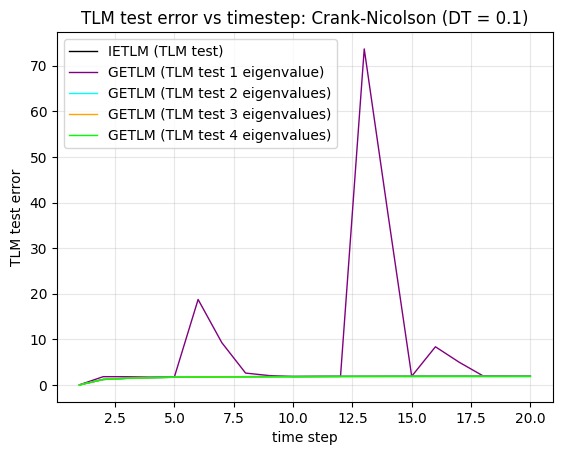

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.plot(x_values, IETLM_F, label='IETLM (TLM test)', color='black', linewidth=1)
# plt.plot(x_values, LETLM_F, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values, GETLM_1_result_F, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values, GETLM_2_result_F, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=1)
plt.plot(x_values, GETLM_3_result_F, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=1)
plt.plot(x_values, GETLM_4_result_F, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=1)

plt.title("TLM test error vs timestep: Crank-Nicolson (DT = 0.1)")
plt.xlabel("time step")
plt.ylabel("TLM test error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

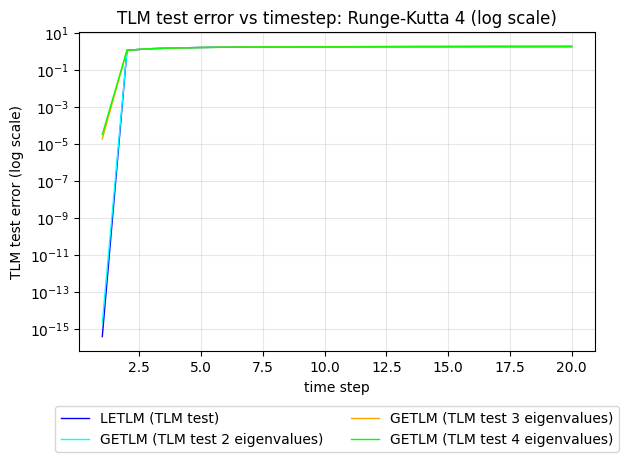

<Figure size 640x480 with 0 Axes>

In [ ]:
# plt.plot(x_values, IETLM_F, label='IETLM (TLM test)', color='black', linewidth=1)
plt.plot(x_values, LETLM_F, label='LETLM (TLM test)', color='blue', linewidth=1)
# plt.plot(x_values, GETLM_1_result_F, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values, GETLM_2_result_F, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=1)
plt.plot(x_values, GETLM_3_result_F, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=1)
plt.plot(x_values, GETLM_4_result_F, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=1)

plt.title("TLM test error vs timestep: Runge-Kutta 4 (log scale)")
plt.xlabel("time step")
plt.ylabel("TLM test error (log scale)")
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    ncols=2,             # Arranges items horizontally instead of vertically
    frameon=True         # Optional: adds a border box around the legend
)


# 3. CRITICAL: Prevent the legend from getting cut off when displaying or saving
plt.tight_layout()
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

In [ ]:
%store -r LETLM_TT_result
%store -r GETLM_2_TT_result

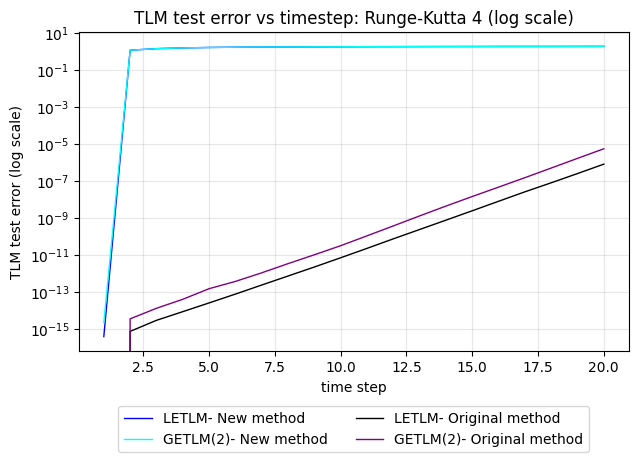

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.plot(x_values, LETLM_F, label='LETLM- New method', color='blue', linewidth=1)
plt.plot(x_values, GETLM_2_result_F, label='GETLM(2)- New method', color='aqua', linewidth=1)


plt.plot(x_values, LETLM_TT_result, label='LETLM- Original method', color='black', linewidth=1)
plt.plot(x_values, GETLM_2_TT_result, label='GETLM(2)- Original method', color='purple', linewidth=1)

plt.title("TLM test error vs timestep: Runge-Kutta 4 (log scale)")
plt.xlabel("time step")
plt.ylabel("TLM test error (log scale)")
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    ncols=2,             # Arranges items horizontally instead of vertically
    frameon=True         # Optional: adds a border box around the legend
)


# 3. CRITICAL: Prevent the legend from getting cut off when displaying or saving
plt.tight_layout()
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()